# 02 Как объясняют агентов и что с этим не так

**Акт 1. Ничего не нужно: ни ключа, ни модели, ни сети.** Живой агент уже
прогнан ноутбуком `03_produce_agentshap_live.ipynb`, его результаты лежат в `data/agentshap/`.
Контрфактуальные запуски — в `data/full_cf_stopwords_results.csv`.

## Трейсинг против объяснения

**Трейс** — запись того, что произошло: какие вызовы, в каком порядке, с какими
аргументами и ответами. Это факт о прогоне, его можно записать полностью
(LangSmith, OpenTelemetry, логи harness).

**Объяснение** — утверждение, *почему* произошло: «агент вызвал `send_money`,
потому что прочитал инъекцию в файле». Это причинное утверждение про мир,
которого не было: без инъекции вызова бы не случилось. Его нельзя записать,
его можно только измерить или вывести.

Почему объяснять агента труднее, чем классическую модель:

| | классическая модель | агент |
|---|---|---|
| выход | число, класс | текст и последовательность действий |
| одно вычисление $v(S)$ | прямой проход | полный прогон агента с вызовами инструментов |
| стохастичность | обычно нет | есть всегда: один прогон — одна выборка |
| градиенты | есть | через API нет |
| сравнение исходов | разность чисел | метрика близости текстов, со своим шумом |
| избыточность | коррелированные признаки | инструменты и правила, которые подменяют друг друга |

Каждая коалиция — отдельный прогон модели. Точный Шепли по $n$ компонентам —
это $2^n$ прогонов, и каждый — случайная величина.

## Что есть для объяснения агентов

Шепли-атрибуция для агентов — активное направление, но готового кода мало.
Проверено 27.09.2026 (GitHub API, PyPI, Semantic Scholar).

| работа | что атрибутирует | код, из коробки | что меряет |
|---|---|---|---|
| **AgentSHAP**, Horovicz, arXiv:2512.12597 (2025) | инструменты агента | да, внутри [GenAISHAP/TokenSHAP](https://github.com/GenAISHAP/TokenSHAP), black-box | Шепли по наличию инструмента; $v(S)$ — близость ответа к полному |
| **TokenSHAP**, Goldshmidt & Horovicz, NLP4Science 2024, doi:10.18653/v1/2024.nlp4science-1.1 | токены промпта | тот же репозиторий, PyPI `tokenshap` 0.2.2 (2024) | то же, по токенам |
| SkillShapley, arXiv:2608.13173 (2026) | шаги-скиллы | нет | Шепли с адаптивным сэмплингом коалиций |
| Understanding and Optimizing Agentic Workflows via Shapley value, arXiv:2502.00510 (2025) | компоненты workflow | — | Шепли |
| ContextCite, Cohen-Wang et al., NeurIPS 2024 | предложения контекста | [MadryLab/context-cite](https://github.com/MadryLab/context-cite), PyPI `context-cite`; нужны logprobs | линейный суррогат на случайных абляциях |
| AttriBoT, Liu et al., arXiv:2411.15102 | куски контекста | [r-three/AttriBoT](https://github.com/r-three/AttriBoT); нужны logprobs | быстрый leave-one-out |
| LLMLingua / LongLLMLingua, EMNLP 2023 / ACL 2024, doi:10.18653/v1/2023.emnlp-main.825, 10.18653/v1/2024.acl-long.91 | токены / куски промпта | [microsoft/LLMLingua](https://github.com/microsoft/LLMLingua), PyPI `llmlingua` | не атрибуция: перплексия под малой LM, для сжатия |
| Mosca et al., обзор SHAP для NLP, COLING 2022 | — | обзор, кода нет | — |
| Jiang et al., How can we know what LMs know?, TACL 2020 | — | архив промптов LPAQA | чувствительность ответа к формулировке, не атрибуция |

Для black-box агента из коробки подключается ровно одно: **AgentSHAP**.
Поэтому разбираем его. Semantic Scholar за девять месяцев показывает у него
одно цитирование, в related work работы про провенанс.

Устройство: $v(S)$ — косинусная близость TF-IDF ответа агента с набором
инструментов $S$ к ответу с полным набором $N$. Вклад инструмента — значение
Шепли по этой игре, эффективность обеспечена нормировкой.

In [1]:
import sys; sys.path.insert(0, "..")
import json
from itertools import combinations
from math import factorial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from agent import NoiseFloor, TOOL_NAMES
from agent.attribution import corrected_contributions, shapley_from_occlusion, tool_occlusion_importance
from bench.stats import bootstrap_order_prob, min_repeats, wilson_ci

pd.set_option("display.precision", 4)
DATA = "../data/agentshap/"

def load_runs(name):
    df = pd.read_csv(DATA + f"{name}_coalitions.csv" if name == "notool" else DATA + f"{name}.csv")
    return df[df.combination_key != "baseline"], df[df.combination_key == "baseline"]

finance, finance_base = load_runs("finance")
notool, notool_base = load_runs("notool")
shap_lib = pd.concat([pd.read_csv(DATA + "finance_shapley.csv"),
                      pd.read_csv(DATA + "notool_shapley.csv")]).set_index("prompt")
nf = NoiseFloor.from_json(DATA + "noise_floor.json")

# Критика A: реализация

## A1. Строк $n$, а не $2^n$

В туториале к `sampling_ratio=0.0` написан комментарий «полный перебор,
$2^n = 16$ комбинаций». Смотрим, что на самом деле лежит в `results_df`.

In [2]:
print(f"промпт: {finance.prompt.iloc[0]!r}")
print(f"строк в results_df: {len(finance)}   (2^n было бы {2 ** len(TOOL_NAMES)})\n")
print(finance[["tools_available", "similarity"]].to_string(index=False))

промпт: "What's the weather in New York and how is AAPL stock doing today?"
строк в results_df: 4   (2^n было бы 16)

                      tools_available  similarity
   calculate+get_news+get_stock_price      0.2256
       calculate+get_news+get_weather      0.2635
 get_news+get_stock_price+get_weather      0.6246
calculate+get_stock_price+get_weather      0.6830


Библиотека перебирает только коалиции «всё, кроме одного»
(`agent_shap.py`, `_get_result_per_combination`, «essential combinations»),
а дополнительные добирает долей `sampling_ratio` от оставшихся. При нуле их нет.
Повод не верить комментариям, включая свои.

## A2. Вырождение Шепли

`sampling_ratio` — параметр `analyze()` (по умолчанию 0.5): какую долю
«необязательных» коалиций досэмплировать. Библиотека всегда прогоняет $n$
коалиций вида $N \setminus \{i\}$, «всё, кроме одного», а из остальных
$2^n - 1 - n$ непустых добирает случайно
$\lfloor (2^n - 1 - n) \cdot \texttt{sampling\_ratio} \rfloor$
(`agent_shap.py`, `_get_result_per_combination`). При `sampling_ratio=1`
перебираются все коалиции, при `sampling_ratio=0` — ни одной
дополнительной. Так что при `sampling_ratio=0` у библиотеки есть только
коалиции $N \setminus \{i\}$.

**Occlusion** (окклюзия, «загораживание») — самый простой метод атрибуции:
убрать один компонент, оставив остальные, и посмотреть, насколько изменился
выход. Изменение и есть важность компонента. Название пришло из компьютерного
зрения: там закрывают серым квадратом кусок картинки и смотрят, упала ли
уверенность классификатора (Zeiler & Fergus, 2014). У AgentSHAP компонент —
инструмент, выход — ответ агента, а изменение меряется через близость
к ответу с полным набором:

$$\mathrm{occ}_i = v(N) - v(N \setminus \{i\}) = 1 - v(N \setminus \{i\}),$$

где $v(N) = 1$ — близость полного ответа к самому себе (к этой единице
вернёмся в A3). Это ровно $n$ коалиций вида «всё, кроме одного», то есть
ровно то, что библиотека прогоняет при `sampling_ratio=0`.

Значение Шепли из одних таких коалиций не посчитать: для него нужны все
$2^n$. Поэтому библиотека делает другое — берёт occlusion и нормирует.
Нормировка восстановлена по формуле ходом:

$$\varphi_i = \frac{\mathrm{occ}_i - \min_j \mathrm{occ}_j}{\sum_k \mathrm{occ}_k - n \min_j \mathrm{occ}_j}$$

Проверяем на всех шести сохранённых прогонах против того, что вернула
сама библиотека.

In [3]:
runs = pd.concat([finance, notool])
check = []
for prompt, g in runs.groupby("prompt", sort=False):
    closed = shapley_from_occlusion(tool_occlusion_importance(g, TOOL_NAMES))
    check.append({"промпт": prompt[:45], "макс. расхождение": np.abs(closed - shap_lib.loc[prompt, TOOL_NAMES]).max()})
pd.DataFrame(check).set_index("промпт")

,макс. расхождение
промпт,
What's the weather in New York and how is AAP,5.5511e-17
What is the capital of France?,1.1102e-16
Who wrote Anna Karenina?,1.1102e-16
Translate 'good morning' into Spanish.,1.6653e-16
What does the acronym CPU stand for?,4.1633e-16
Name three primary colors.,1.6653e-16


Совпадение до $10^{-16}$, то есть до машинной точности: закрытая форма
и есть то, что считает библиотека.

Что из неё следует. Перепишем её как

$$\varphi_i = a \cdot \mathrm{occ}_i + b, \qquad
a = \frac{1}{\sum_k \mathrm{occ}_k - n \min_j \mathrm{occ}_j} > 0, \qquad
b = -a \min_j \mathrm{occ}_j .$$

На одном промпте $a$ и $b$ — константы, общие для всех инструментов,
и $a > 0$. Значит «Шепли» здесь — **строго возрастающая аффинная функция
от occlusion**: чем больше occlusion, тем больше $\varphi$, и никак иначе.
Отсюда два следствия:

1. **Порядок инструментов совпадает с occlusion тождественно**, на любом
   промпте, при любых значениях близости. Никакой информации сверх
   occlusion «Шепли» не добавляет: это тот же occlusion, сдвинутый
   и растянутый.
2. **Минимальный инструмент всегда получает точный ноль:** при
   $\mathrm{occ}_i = \min_j \mathrm{occ}_j$ числитель обращается в ноль.
   Не потому, что инструмент не влиял, а потому, что он минимальный.
   К этому вернёмся в A4.

*Примечание.* На тех же коалициях вырождаются и другие методы: LIME из
туториала сводится к $\tfrac{3}{7}\,\mathrm{occ}_i + c$. Так что «методы
согласны» здесь ничего не подтверждает: это одна функция в разных масштабах.

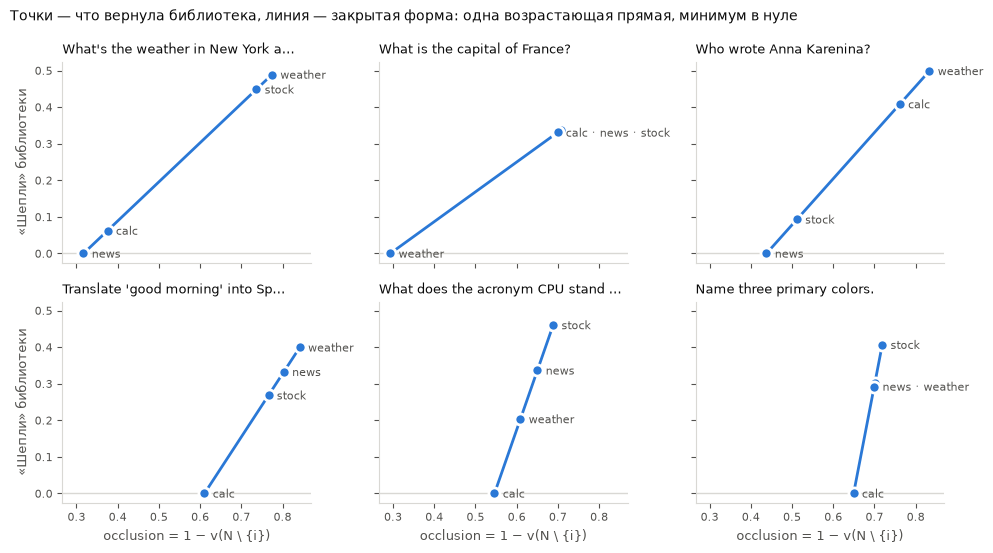

In [4]:
# график зависимости: «Шепли» библиотеки против occlusion, по промпту на панель
INK, INK_2, GRID, SERIES = "#0b0b0b", "#52514e", "#d9d8d4", "#2a78d6"
SHORT = {"get_weather": "weather", "get_stock_price": "stock", "calculate": "calc", "get_news": "news"}

fig, axes = plt.subplots(2, 3, figsize=(10, 5.6), sharex=True, sharey=True)
for ax, (prompt, g) in zip(axes.flat, runs.groupby("prompt", sort=False)):
    occ = tool_occlusion_importance(g, TOOL_NAMES)
    phi = shap_lib.loc[prompt, TOOL_NAMES].astype(float)
    x = np.linspace(occ.min(), occ.max(), 2)
    a = 1 / (occ.sum() - len(occ) * occ.min())
    ax.plot(x, a * (x - occ.min()), color=SERIES, lw=2, zorder=1)          # закрытая форма
    ax.scatter(occ, phi, s=64, color=SERIES, edgecolor="white", linewidth=2, zorder=2)  # библиотека
    # точки, которые почти совпали, подписываем одной меткой
    groups = []
    for tool in phi.sort_values().index:
        if groups and abs(phi[tool] - phi[groups[-1][0]]) < 0.03 and abs(occ[tool] - occ[groups[-1][0]]) < 0.03:
            groups[-1].append(tool)
        else:
            groups.append([tool])
    for grp in groups:
        ax.annotate(" · ".join(SHORT[t] for t in grp), (occ[grp[0]], phi[grp[0]]), xytext=(6, -3),
                    textcoords="offset points", fontsize=8, color=INK_2)
    ax.axhline(0, color=GRID, lw=1, zorder=0)
    ax.set_title(prompt if len(prompt) <= 34 else prompt[:32] + "…", fontsize=9, color=INK, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=INK_2, labelsize=8)
for ax in axes[1]:
    ax.set_xlabel("occlusion = 1 − v(N \\ {i})", fontsize=9, color=INK_2)
for ax in axes[:, 0]:
    ax.set_ylabel("«Шепли» библиотеки", fontsize=9, color=INK_2)
fig.suptitle("Точки — что вернула библиотека, линия — закрытая форма: одна возрастающая прямая, минимум в нуле",
             fontsize=10, color=INK, x=0.01, ha="left")
plt.tight_layout(); plt.show()

## A3. Недостижимый baseline

В `token_shap/base.py` у `OpenAIModel.generate()` и `generate_with_tools()`
зашито `temperature=0.5` (строки 328 и 370 в версии `28b2f2c`), параметра нет.
Значит два прогона с одним и тем же полным тулсетом дают разные ответы,
и близость ответа к самому себе — не единица, как в формуле, а
$\nu = \mathbb E[\cos(\text{ответ}(N), \text{ответ}'(N))] < 1$.

noise floor  nu = 0.6653 ± 0.1079   (27 сравнений, 3 промпта, qwen2.5:3b)
смещение   1 - nu = 0.3347
поведенческий шум: 0.0% прогонов с другим набором инструментов


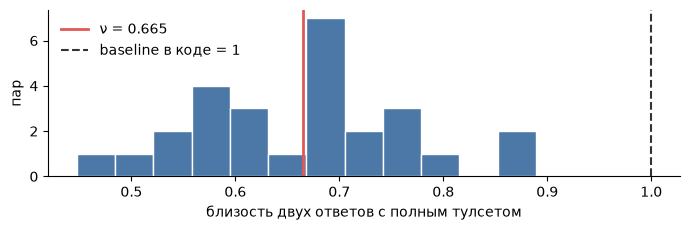

In [5]:
print(nf)
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.hist(nf.samples, bins=12, color="#4C78A8", edgecolor="white")
ax.axvline(nf.nu, color="#E45756", lw=2, label=f"ν = {nf.nu:.3f}")
ax.axvline(1.0, color="#333", ls="--", lw=1.5, label="baseline в коде = 1")
ax.set_xlabel("близость двух ответов с полным тулсетом")
ax.set_ylabel("пар")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## A4. Аксиома dummy

Инструмент, который агент не вызывал, обязан получить ноль. Пять промптов,
где не нужен ни один инструмент.

In [6]:
table = shap_lib.loc[notool.prompt.unique(), TOOL_NAMES]
table["сумма"] = table.sum(axis=1)
table["точных нулей"] = (table[TOOL_NAMES].abs() < 1e-12).sum(axis=1)
print(table.round(4).to_string())

used = [c for c in notool.columns if c.startswith("used_")]
calls = pd.concat([notool, notool_base]).groupby("prompt", sort=False)[used].sum()
print("\nвызовы инструментов на этих промптах, по всем прогонам analyze():")
print(calls.to_string())

                                        get_weather  get_stock_price  calculate  get_news  сумма  точных нулей
prompt                                                                                                        
What is the capital of France?               0.0000           0.3381     0.3305    0.3314    1.0             1
Who wrote Anna Karenina?                     0.4989           0.0931     0.4080    0.0000    1.0             1
Translate 'good morning' into Spanish.       0.3993           0.2683     0.0000    0.3324    1.0             1
What does the acronym CPU stand for?         0.2034           0.4602     0.0000    0.3364    1.0             1
Name three primary colors.                   0.3012           0.4065     0.0000    0.2923    1.0             1

вызовы инструментов на этих промптах, по всем прогонам analyze():
                                        used_get_news
prompt                                               
What is the capital of France?                  

Сумма в каждой строке ровно 1: эффективность выполняется нормировкой, и она же
заставляет раздать единицу инструментам, которые агент не вызывал. Но 
один инструмент на строку получает точный ноль — тот, у которого минимальный
occlusion. Это следует из формы: нормировка сдвигает минимум в ноль.
Аксиома dummy «выполняется» ровно для одного инструмента на промпт, случайно.

## A5. Можно ли это починить заменой baseline

Идея: если смещение идёт от недостижимой единицы, заменим её измеренным
потолком $\nu$:

```python
contribution_i = 1 - similarity(N \ {i})              # было
contribution_i = max(0, nu - similarity(N \ {i}))     # стало
```

Для невызванного инструмента `similarity` держится около $\nu$, и вклад
садится в ноль. Проверяемое предсказание: средний occlusion на промптах
без инструментов должен быть близок к $1 - \nu$.

Сначала берём $\nu$, измеренный на промптах **с** инструментами.

In [7]:
check = pd.DataFrame({
    "средний occlusion": notool.groupby("prompt", sort=False)
        .apply(lambda g: tool_occlusion_importance(g, TOOL_NAMES).mean()),
})
check["предсказание 1 - ν (глобальный)"] = nf.bias
check.round(3)

,средний occlusion,предсказание 1 - ν (глобальный)
prompt,,
What is the capital of France?,0.600,0.335
Who wrote Anna Karenina?,0.636,0.335
Translate 'good morning' into Spanish.,0.755,0.335
What does the acronym CPU stand for?,0.623,0.335
Name three primary colors.,0.692,0.335


Предсказание не сходится: occlusion почти вдвое больше. Потолок близости
зависит от промпта. Ответ с данными инструмента почти детерминирован,
свободный текст («назовите три основных цвета») — нет. Поэтому ноутбук `03_produce_agentshap_live.ipynb`
мерил $\nu$ ещё и на каждом промпте без инструментов, по десять прогонов.

In [8]:
nf_p = {p: NoiseFloor(**d) for p, d in json.loads(open(DATA + "noise_floor_notool.json").read()).items()}

rows = []
for prompt, g in notool.groupby("prompt", sort=False):
    n = nf_p[prompt]
    corrected = corrected_contributions(g, TOOL_NAMES, n.nu)
    rows.append({"промпт": prompt[:40], "ν на промпте": n.nu, "σ": n.sd,
                 "средний occlusion": tool_occlusion_importance(g, TOOL_NAMES).mean(),
                 "предсказание 1 - ν": 1 - n.nu,
                 "макс. вклад после поправки": corrected.max(),
                 "все вклады ≤ 2σ": bool((corrected <= 2 * n.sd).all())})
pd.DataFrame(rows).set_index("промпт").round(3)

,ν на промпте,σ,средний occlusion,предсказание 1 - ν,макс. вклад после поправки,все вклады ≤ 2σ
промпт,,,,,,
What is the capital of France?,0.316,0.079,0.600,0.684,0.024,True
Who wrote Anna Karenina?,0.318,0.102,0.636,0.682,0.151,True
Translate 'good morning' into Spanish.,0.308,0.104,0.755,0.692,0.149,True
What does the acronym CPU stand for?,0.424,0.141,0.623,0.576,0.113,True
Name three primary colors.,0.274,0.048,0.692,0.726,0.000,True


С $\nu$ того же промпта предсказание сходится, и после поправки все вклады
невызванных инструментов лежат в пределах двух стандартных отклонений шума:
dummy выполняется. Но честная формулировка починки длиннее одной строки:

1. baseline — не единица, а $\nu$, **измеренный на том же промпте**;
2. это ещё десяток прогонов на каждый объясняемый промпт;
3. нормировать нельзя: деление почти нулевых вкладов на их почти нулевую
   сумму заново раздувает шум до единицы;
4. и даже тогда «ноль» означает «неотличимо от шума на этих прогонах»,
   а не «инструмент не влиял».

Реализационная критика чинится, но каждая починка стоит прогонов.

# Критика B: вопрос не тот

Всё, что выше, чинится: полный перебор вместо «всё, кроме одного», измеренный
baseline, нормировка без сдвига минимума. Но вернемся к необзодимости и достаточности. 

**Watson et al. (UAI 2021), Proposition 1.** Функция ценности SHAP
$v(S) = \mathbb E[f(x_S, X_R)]$ тождественно равна вероятности
**достаточности** фактора «$x_S$ зафиксированы, остальное из фона».
У AgentSHAP то же самое: $v(S)$ — насколько ответ с инструментами $S$
похож на полный, то есть хватает ли $S$, чтобы получить тот же ответ.
Значение Шепли — средний прирост достаточности.

Вопрос «без чего ответ был бы другим» — это **необходимость**, и она
в этой конструкции не задаётся нигде (ноутбук 01). Критика верна для
идеальной реализации и переживает любой багфикс.

**Теорема об избыточности.** Если инструменты $i$ и $j$ взаимозаменяемы:
для любого $S \subseteq N \setminus \{i, j\}$ выполнено
$v(S \cup \{i\}) = v(S \cup \{j\}) = v(S \cup \{i, j\})$, — то
$\varphi_i = \varphi_j > 0$, но $\text{PN}(i) = \text{PN}(j) = 0$.

*Доказательство.* PN = 0: без $i$ остаётся $j$, и $v(N \setminus \{i\}) = v(N)$.
Равенство даёт симметрия. Положительность: маргинальный вклад $i$
положителен на коалициях без $i$ и без $j$.

Два поисковых инструмента и калькулятор, точный Шепли полным перебором:

In [9]:
def exact_shapley(v, players):
    n = len(players)
    return {i: sum(factorial(k) * factorial(n - k - 1) / factorial(n)
                   * (v(frozenset(S) | {i}) - v(frozenset(S)))
                   for k in range(n) for S in combinations([p for p in players if p != i], k))
            for i in players}

def v(S):
    return (1.0 if S & {"search_a", "search_b"} else 0.0) + (0.4 if "calc" in S else 0.0)

full = frozenset({"search_a", "search_b", "calc"})
pd.DataFrame({"Шепли": exact_shapley(v, sorted(full)),
              "PN": {i: float(v(full - {i}) != v(full)) for i in sorted(full)}})

,Шепли,PN
calc,0.4,1.0
search_a,0.5,0.0
search_b,0.5,0.0


Поиск A и поиск B делят вклад поровну, хотя убери любой — ответ не изменится.
При $k$ взаимозаменяемых инструментах каждый получает $1/k$: чем больше
перекрытие, тем ничтожнее выглядит каждый. Для детектора с перекрывающимися
правилами это значит, что «важность правила» не определена.

# Оценка стоимости на словах. 

Хорошо, будем мерить необходимость напрямую, вмешательством. 468 реальных
запусков агента: убрали слово из промпта, посмотрели, перестал ли агент
вызывать инструмент. Это не оценка, а прямое измерение.

In [10]:
cf = pd.read_csv("../data/full_cf_stopwords_results.csv")
print(cf.head(3).to_string(index=False), "\n")

pn = cf.groupby("tool")["flipped"].agg(["sum", "count"])
pn["PN"] = pn["sum"] / pn["count"]
pn = pn.sort_values("PN", ascending=False)
for tool, row in pn.iterrows():
    lo, hi = wilson_ci(int(row["sum"]), int(row["count"]))
    print(f"{tool:<18} PN = {row['PN']:6.1%}  [{lo:5.1%}, {hi:5.1%}]  n = {int(row['count'])}")

       tool removed_words  called_before  called_after  flipped
get_weather  weather+like           True         False     True
get_weather  weather+like           True         False     True
get_weather  weather+like           True          True    False 

get_news           PN =  51.9%  [43.4%, 60.4%]  n = 129
get_stock_price    PN =  26.6%  [19.7%, 34.8%]  n = 128
get_weather        PN =  16.9%  [11.4%, 24.3%]  n = 130
calculate          PN =   2.5%  [ 0.7%,  8.6%]  n = 81


Интервал Уилсона, а не нормальное приближение: при малых $n$ и долях у края
нормальное врёт. Сколько прогонов нужно, чтобы по таким частотам вообще
утверждать порядок? Симулируем эксперимент с $n$ прогонами на инструмент
при истинных частотах, равных измеренным.

Ничья — отдельная категория: данные порядок не определяют вовсе.

In [11]:
rates = pn["PN"].to_dict()
print(f"{'n на инструмент':>16} {'верный порядок':>15} {'ничья':>8} {'неверный':>9}")
for n_per in (3, 10, 50, 100):
    r = bootstrap_order_prob(rates, n_per, n_boot=50_000)
    print(f"{n_per:>16} {r['p_correct']:>15.1%} {r['p_tie']:>8.1%} {r['p_wrong']:>9.1%}")

 n на инструмент  верный порядок    ничья  неверный
               3            0.7%    98.4%      0.9%
              10           28.6%    51.5%     19.9%
              50           84.3%     5.5%     10.2%
             100           94.1%     1.8%      4.0%


Сколько прогонов на инструмент нужно, чтобы отличить соседей по порядку.
Стандартная формула размера выборки для двух долей, двусторонний тест,
$\alpha = 0.05$, мощность **0.90**.

In [12]:
pairs = list(zip(pn.index, pn.index[1:]))
for t1, t2 in pairs:
    print(f"{t1:>16} против {t2:<16} мощность 0.90: {min_repeats(rates[t1], rates[t2], power=0.90):>4}   "
          f"0.80: {min_repeats(rates[t1], rates[t2], power=0.80):>4}")

print("\nноль срабатываний из n — это интервал, а не ноль:")
for n in (3, 30, 170):
    lo, hi = wilson_ci(0, n)
    print(f"  0 из {n:>3}: [{lo:.3f}, {hi:.3f}]")

        get_news против get_stock_price  мощность 0.90:   76   0.80:   57
 get_stock_price против get_weather      мощность 0.90:  383   0.80:  287
     get_weather против calculate        мощность 0.90:   86   0.80:   65

ноль срабатываний из n — это интервал, а не ноль:
  0 из   3: [0.000, 0.561]
  0 из  30: [0.000, 0.114]
  0 из 170: [0.000, 0.022]


Чтобы отличить `get_stock_price` от `get_weather`, нужно **383 прогона**
на инструмент. А ноль ложных срабатываний из 170 — это
«реже, чем 2.2 %». Так и надо отчитываться о защите,
которая на тестовом наборе ни разу не ошиблась.

## Попарное сравнение

Когда меряете необходимость на стохастическом агенте, сравнивайте $i$-й прогон
без компонента с $i$-м прогоном базлайна, а не все прогоны с одним общим
базлайном. Почему.

Пусть исход бинарный (вызван инструмент или нет), с полным набором он
случается с вероятностью $q_1$, без компонента — с $q_0$. Попарная оценка
несмещённо оценивает $P(\text{исходы двух независимых прогонов различаются})$.
Оценка с одним базлайном — ту же величину **при условии** случайного первого
прогона: если базлайну не повезло, неверны все $n$ сравнений разом.

В данных выше `called_before` всегда `True`, так что там разницы нет.
Покажем на симуляции.

In [13]:
rng = np.random.default_rng(0)
q1, q0, n, trials = 0.8, 0.2, 30, 20_000
target = q1 * (1 - q0) + (1 - q1) * q0          # P(исходы различаются)

base = rng.random((trials, n)) < q1
after = rng.random((trials, n)) < q0
paired = (base != after).mean(axis=1)
single = (base[:, :1] != after).mean(axis=1)

print(f"истинная доля расхождений: {target:.3f}")
for name, est in [("попарно", paired), ("один базлайн", single)]:
    print(f"{name:<13} среднее {est.mean():.3f}   разброс (sd) {est.std():.3f}   "
          f"доля оценок дальше 0.15 от истины {(np.abs(est - target) > 0.15).mean():.1%}")

истинная доля расхождений: 0.680
попарно       среднее 0.679   разброс (sd) 0.085   доля оценок дальше 0.15 от истины 7.7%
один базлайн  среднее 0.682   разброс (sd) 0.249   доля оценок дальше 0.15 от истины 54.2%


Среднее у обеих оценок одно, а разброс у оценки с одним базлайном в разы
больше: она бимодальна, в зависимости от того, каким вышел первый прогон.
Попарное сравнение стоит столько же прогонов и не ставит всё на один.

# Итог акта 1

1. **Критика A (реализация):** при `sampling_ratio=0` Шепли вырождается
   в нормированный occlusion, baseline недостижим, нормировка обнуляет минимальный
   инструмент. Это чинится.
2. **Критика B (концепция):** даже починенный метод меряет достаточность.
   При избыточности он систематически раздаёт вклад тем, кто не необходим.
   Это не чинится.
3. **Честное измерение необходимости** возможно, но стоит сотни прогонов
   на компонент. Отсюда вопрос акта 2: обязательно ли вообще мерить?